# 02.7 · Decision tree regressor: predicting with questions

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/02-regression/07-decision-tree-regressor/lesson.ipynb)

Read the [README](README.md) and do the variance-reduction table by hand. Here: the same table in code, scikit-learn agreeing with it, the staircase vs the line, depth and overfitting, and trees on the real customers.

## 1. Variance reduction, in code

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd, numpy as np
six = pd.DataFrame({"customer": list("ABCDEF"),
                    "days_since_last": [1, 2, 3, 10, 20, 30],
                    "spend": [120, 100, 110, 40, 30, 20]})
six

,customer,days_since_last,spend
0,A,1,120
1,B,2,100
2,C,3,110
3,D,10,40
4,E,20,30
5,F,30,20


In [2]:
def var(a):
    return ((a - a.mean())**2).mean()

x = six["days_since_last"].to_numpy(float); y = six["spend"].to_numpy(float)
parent = var(y)
print(f"parent variance {parent:.1f}\n")
rows = []
for t in [1.5, 2.5, 6.5, 15, 25]:
    L, R = y[x <= t], y[x > t]
    weighted = (len(L) * var(L) + len(R) * var(R)) / len(y)
    rows.append({"threshold": t, "left mean": L.mean(), "Var(L)": var(L), "right mean": R.mean(),
                 "Var(R)": var(R), "weighted": weighted, "reduction Δ": parent - weighted})
pd.DataFrame(rows).round(1)

parent variance 1666.7



,threshold,left mean,Var(L),right mean,Var(R),weighted,reduction Δ
0,1.5,120.0,0.0,60.0,1400.0,1166.7,500.0
1,2.5,110.0,100.0,50.0,1250.0,866.7,800.0
2,6.5,110.0,66.7,30.0,66.7,66.7,1600.0
3,15.0,92.5,968.8,25.0,25.0,654.2,1012.5
4,25.0,80.0,1400.0,20.0,0.0,1166.7,500.0


`days_since_last ≤ 6.5` wins with Δ = 1600. Now let scikit-learn choose.

In [3]:
from sklearn.tree import DecisionTreeRegressor, export_text
X = six[["days_since_last"]]
stump = DecisionTreeRegressor(max_depth=1).fit(X, y)
print(export_text(stump, feature_names=["days_since_last"]))
print("predictions for 4, 25 and 100 days:", stump.predict(pd.DataFrame({"days_since_last": [4, 25, 100]})))

|--- days_since_last <= 6.50
|   |--- value: [110.00]
|--- days_since_last >  6.50
|   |--- value: [30.00]

predictions for 4, 25 and 100 days: [110.  30.  30.]


## 2. Staircase vs line

A tree's prediction is flat inside each leaf and jumps at each threshold. Grow the depth and watch the staircase chase every point.

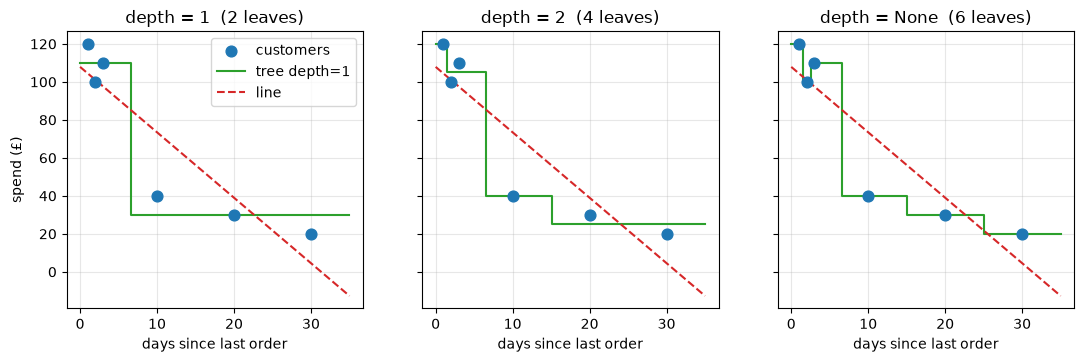

In [4]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
grid = pd.DataFrame({"days_since_last": np.linspace(0, 35, 300)})
line = LinearRegression().fit(X, y)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, depth in zip(axes, [1, 2, None]):
    t = DecisionTreeRegressor(max_depth=depth).fit(X, y)
    ax.scatter(x, y, s=60, zorder=5, label="customers")
    ax.step(grid["days_since_last"], t.predict(grid), where="post", color="tab:green", label=f"tree depth={depth}")
    ax.plot(grid["days_since_last"], line.predict(grid), color="tab:red", linestyle="--", label="line")
    ax.set(title=f"depth = {depth}  ({t.get_n_leaves()} leaves)", xlabel="days since last order"); ax.grid(alpha=.3)
axes[0].set_ylabel("spend (£)"); axes[0].legend()
plt.show()

Unlimited depth: six leaves for six customers, training error zero, and a prediction that jumps around with every noise wiggle. The line misses the threshold at ~6 days completely but behaves sensibly beyond 30 days; the tree repeats £20 forever.

## 3. Twenty customers, three features

Trees pick a different feature at each node, so interactions ("recent *and* frequent") come for free.

In [5]:
cust20 = pd.read_csv(data_path("shopwave_customers_small.csv"))
cust20.head()

,customer_id,visits_last_month,items_last_month,days_since_last,country,spend_next_month,churned
0,C001,2,2,55,UK,27.61,1
1,C002,11,8,44,FR,220.42,0
2,C003,10,6,22,DE,176.21,0
3,C004,7,6,58,UK,127.58,1
4,C005,7,5,25,FR,150.95,1


In [6]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def report(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"{name:<28} MAE £{mae:8.1f}   RMSE £{rmse:8.1f}   R² {r2:6.3f}")

feats = ["visits_last_month", "items_last_month", "days_since_last"]
y20 = cust20["spend_next_month"]
for depth in [1, 2, 3, 5, None]:
    t = DecisionTreeRegressor(max_depth=depth, random_state=0).fit(cust20[feats], y20)
    report(f"tree depth={depth} ({t.get_n_leaves()} leaves)", y20, t.predict(cust20[feats]))
report("line (3 features)", y20, LinearRegression().fit(cust20[feats], y20).predict(cust20[feats]))

tree depth=1 (2 leaves)      MAE £    31.2   RMSE £    36.7   R²  0.716
tree depth=2 (4 leaves)      MAE £    16.7   RMSE £    20.4   R²  0.912
tree depth=3 (8 leaves)      MAE £     7.5   RMSE £     9.8   R²  0.980
tree depth=5 (17 leaves)     MAE £     1.0   RMSE £     2.1   R²  0.999
tree depth=None (20 leaves)  MAE £     0.0   RMSE £     0.0   R²  1.000
line (3 features)            MAE £     7.8   RMSE £     9.0   R²  0.983


In [7]:
t2 = DecisionTreeRegressor(max_depth=2, random_state=0).fit(cust20[feats], y20)
print(export_text(t2, feature_names=feats))

|--- items_last_month <= 4.00
|   |--- days_since_last <= 21.00
|   |   |--- value: [86.95]
|   |--- days_since_last >  21.00
|   |   |--- value: [40.00]
|--- items_last_month >  4.00
|   |--- items_last_month <= 6.50
|   |   |--- value: [166.57]
|   |--- items_last_month >  6.50
|   |   |--- value: [233.05]



Training error falls to zero as depth grows: that is memorisation, not skill (02.6). The depth-2 tree is readable: two questions, four spend bands.

## 4. The real customers

Six features, held-out test set (as in 02.6; Module 04 makes it routine). Line vs trees of growing depth.

In [8]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import sys, pandas as pd
sys.path.insert(0, str(data_path("download.py").parent))
from download import ensure_online_retail

raw = pd.read_excel(ensure_online_retail(), sheet_name="Year 2010-2011")
print(raw.shape)
raw.head()


def clean_retail(df):
    """The standard ShopWave cleaning used from lesson 01.5 onwards."""
    out = df.copy()
    out = out[~out["Invoice"].astype(str).str.startswith("C")]   # drop cancellations
    out = out[(out["Quantity"] > 0) & (out["Price"] > 0)]         # drop returns / free items
    out = out.dropna(subset=["Customer ID"])                       # drop guest checkouts
    out = out.drop_duplicates()
    out["Customer ID"] = out["Customer ID"].astype(int)
    out["Revenue"] = out["Quantity"] * out["Price"]
    return out

sales = clean_retail(raw)
print(f"{len(raw):,} rows → {len(sales):,} after cleaning")


cutoff = pd.Timestamp("2011-09-01")
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]

cust = past.groupby("Customer ID").agg(
    orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
    products=("StockCode", "nunique"), items=("Quantity", "sum"),
    first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"),
    country=("Country", "first"))
cust["avg_order"] = cust["spend"] / cust["orders"]
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
cust["spend_next_quarter"] = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust = cust.drop(columns=["first_order", "last_order"])
print(f"{len(cust):,} customers; features from before {cutoff.date()}, target = spend Sep–Nov 2011")
cust.head()

(541910, 8)
541,910 rows → 392,693 after cleaning
3,317 customers; features from before 2011-09-01, target = spend Sep–Nov 2011


,orders,spend,products,items,country,avg_order,tenure_days,days_since_last,spend_next_quarter
Customer ID,,,,,,,,,
12346,1,77183.60,1,74215,United Kingdom,77183.600000,225,225,0.00
12347,5,2790.86,82,1590,Iceland,558.172000,267,29,1294.32
12348,3,1487.24,22,2124,Finland,495.746667,258,148,310.00
12350,1,334.40,17,197,Norway,334.400000,210,210,0.00
12352,5,1561.81,26,254,Norway,312.362000,196,162,944.23


In [9]:
from sklearn.model_selection import train_test_split
feats_real = ["orders", "spend", "products", "avg_order", "tenure_days", "days_since_last"]
X_tr, X_te, y_tr, y_te = train_test_split(cust[feats_real], cust["spend_next_quarter"], test_size=0.2, random_state=42)

print("                              ---- TRAIN ----                    ---- TEST ----")
line = LinearRegression().fit(X_tr, y_tr)
print(f"{'line':<22} R² {r2_score(y_tr, line.predict(X_tr)):.3f}                         ", end=""); report("", y_te, line.predict(X_te))
for depth in [2, 4, 8, None]:
    t = DecisionTreeRegressor(max_depth=depth, random_state=0).fit(X_tr, y_tr)
    print(f"{'tree depth=' + str(depth):<22} R² {r2_score(y_tr, t.predict(X_tr)):.3f}                         ", end=""); report("", y_te, t.predict(X_te))

                              ---- TRAIN ----                    ---- TEST ----
line                   R² 0.726                                                      MAE £   769.8   RMSE £  3779.0   R²  0.651
tree depth=2           R² 0.705                                                      MAE £   952.4   RMSE £  4864.4   R²  0.421
tree depth=4           R² 0.791                                                      MAE £   863.3   RMSE £  4715.4   R²  0.456
tree depth=8           R² 0.970                                                      MAE £   800.7   RMSE £  4911.0   R²  0.410
tree depth=None        R² 1.000                                                      MAE £   921.6   RMSE £  4755.4   R²  0.447


Two things to read off the table:

1. **Depth and overfitting.** Training R² rises with depth to 1.0; test R² peaks at a shallow depth and then falls. Same story as 02.6 with a different model.
2. **The line wins here.** A handful of wholesalers spend tens of thousands; they end up alone in leaves, and a leaf can only predict the mean of what it saw. The line's "£0.49 per past pound" keeps scaling. Trees are not better than lines, they are shaped differently, and this target rewards a slope.

Now the thing customer success actually asked for.

In [10]:
rule = DecisionTreeRegressor(max_depth=2, min_samples_leaf=50, random_state=0).fit(X_tr, y_tr)
print(export_text(rule, feature_names=feats_real, show_weights=True))

|--- spend <= 8873.41
|   |--- spend <= 2310.86
|   |   |--- value: [355.68]
|   |--- spend >  2310.86
|   |   |--- value: [1638.20]
|--- spend >  8873.41
|   |--- value: [11924.32]



Read it as rules: *if past spend is above about £8,900, expect over £10,000; if it is £2,300–8,900, expect about £1,600; below that, expect a few hundred.* Three bands, one feature asked twice, something a person can act on. (With 50 customers per leaf the tree never found recency worth a split; the big question on this table is simply "how much did they spend before".) That readability is why trees survive even when a line scores higher.

## Quiz answers

1. The mean target of the training rows that reached that leaf.
2. It tries every feature and every threshold between consecutive values and keeps the one with the largest variance reduction (parent variance minus size-weighted child variance).
3. It keeps splitting until each leaf holds one row (or identical rows); the leaf mean then equals the row's own target.
4. A tree routes it to the edge leaf and predicts that leaf's mean, no matter how far out the value is. A line keeps extending the slope.
5. Tree: readable rules, thresholds and interactions, no scaling needed. Line: extrapolates, stable, better when the relationship really is smooth.

**Next:** [02.P Mini-project](../project/)